In [1]:
import pandas as pd

df = pd.read_csv('/content/amazon_prime_titles.csv')

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,"March 30, 2021",2014,NaN,113 min,"Comedy, Drama",A small fishing village must procure a local d...
1,s2,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,"March 30, 2021",2018,13+,110 min,"Drama, International",A Metro Family decides to fight a Cyber Crimin...
2,s3,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,"March 30, 2021",2017,NaN,74 min,"Action, Drama, Suspense",After a man discovers his wife is cheating on ...
3,s4,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, Beyoncé, Britney...",United States,"March 30, 2021",2014,NaN,69 min,Documentary,"Pink breaks the mold once again, bringing her ..."
4,s5,Movie,Monster Maker,Giles Foster,"Harry Dean Stanton, Kieran O'Brien, George Cos...",United Kingdom,"March 30, 2021",1989,NaN,45 min,"Drama, Fantasy",Teenage Matt Banting wants to work with a famo...


In [2]:
# Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (9668, 12)

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9668 entries, 0 to 9667
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       9668 non-null   object
 1   type          9668 non-null   object
 2   title         9668 non-null   object
 3   director      7585 non-null   object
 4   cast          8435 non-null   object
 5   country       672 non-null    object
 6   date_added    155 non-null    object
 7   release_year  9668 non-null   int64 
 8   rating        9331 non-null   object
 9   duration      9668 non-null   object
 10  listed_in     9668 non-null   object
 11  description   9668 non-null   object
dtypes: int64(1), object(11)
memory usage: 906.5+ KB


In [3]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
show_id            0
type               0
title              0
director        2083
cast            1233
country         8996
date_added      9513
release_year       0
rating           337
duration           0
listed_in          0
description        0
dtype: int64

Total Missing Values: 22162


In [4]:
# Fill missing values
columns = ['director', 'cast', 'country', 'rating', 'date_added']

for col in columns:
    df[col] = df[col].fillna('Unknown')

# Check missing values again
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

Total Missing Values: 0


In [5]:
# Check duplicate records
print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 0


In [6]:
# Remove duplicate records
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (9668, 12)


In [7]:
# Count Movies and TV Shows
content_type = df['type'].value_counts()

print("Content Type Distribution:")
print(content_type)

Content Type Distribution:
type
Movie      7814
TV Show    1854
Name: count, dtype: int64


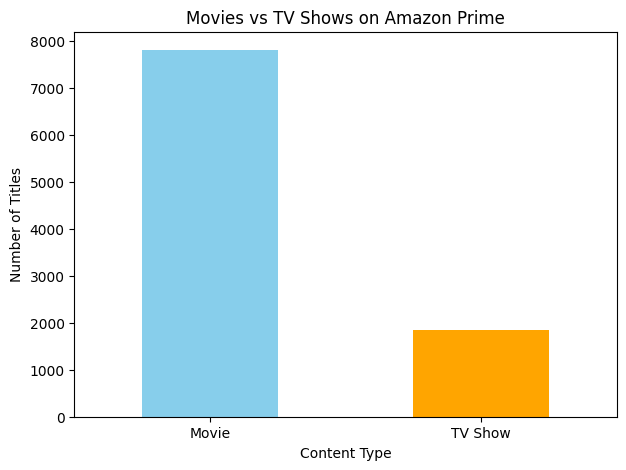

In [8]:
import matplotlib.pyplot as plt

content_type.plot(
    kind='bar',
    color=['skyblue', 'orange'],
    figsize=(7, 5)
)

plt.title('Movies vs TV Shows on Amazon Prime')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.show()

In [9]:
# Count top 10 genres
genres = df['listed_in'].str.split(', ').explode()

top_genres = genres.value_counts().head(10)

print("Top 10 Genres:")
print(top_genres)

Top 10 Genres:
listed_in
Drama               3687
Comedy              2099
Action              1657
Suspense            1501
Kids                1085
Documentary          993
Special Interest     980
Horror               875
Romance              674
Animation            547
Name: count, dtype: int64


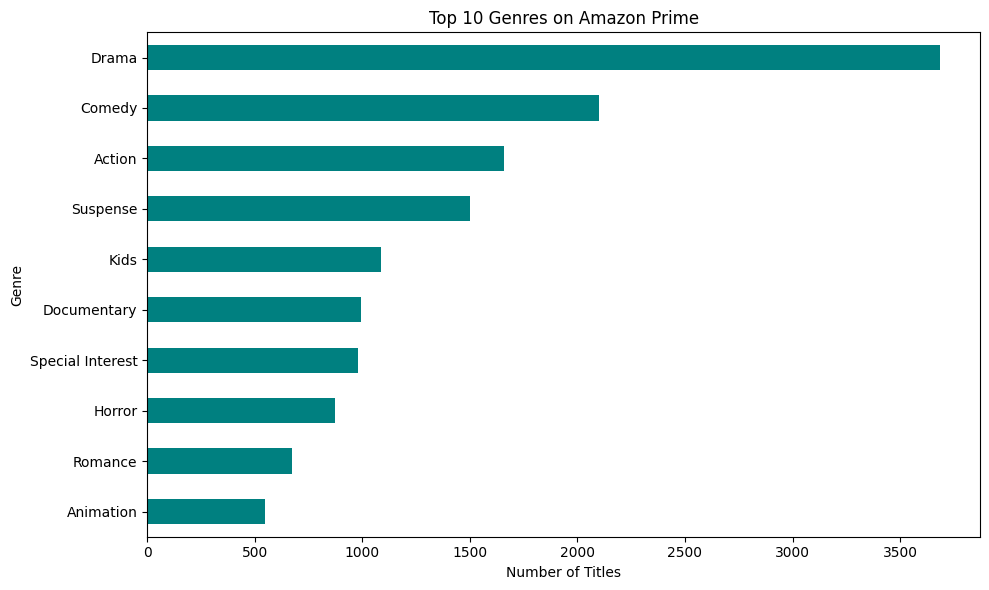

In [10]:
plt.figure(figsize=(10, 6))

top_genres.sort_values().plot(
    kind='barh',
    color='teal'
)

plt.title('Top 10 Genres on Amazon Prime')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

In [11]:
# Count content ratings
ratings = df['rating'].value_counts().head(10)

print("Top 10 Content Ratings:")
print(ratings)

Top 10 Content Ratings:
rating
13+        2117
16+        1547
ALL        1268
18+        1243
R          1010
PG-13       393
7+          385
Unknown     337
PG          253
NR          223
Name: count, dtype: int64


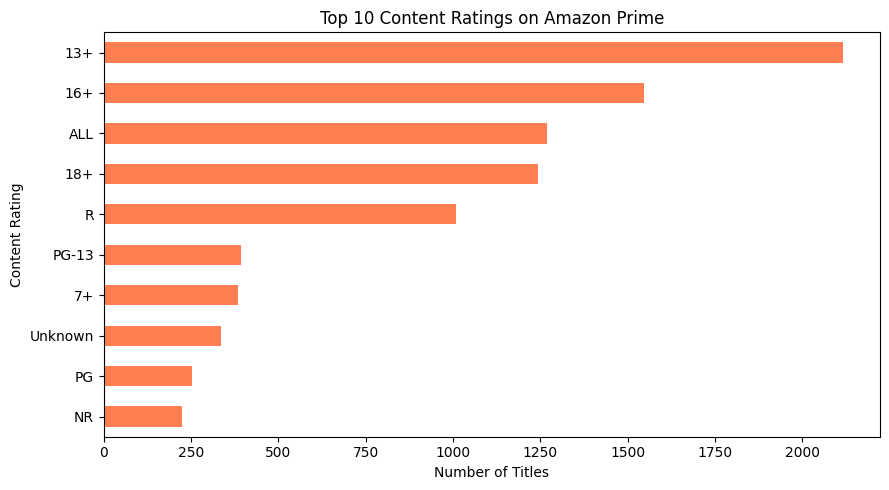

In [12]:
plt.figure(figsize=(9, 5))

ratings.sort_values().plot(
    kind='barh',
    color='coral'
)

plt.title('Top 10 Content Ratings on Amazon Prime')
plt.xlabel('Number of Titles')
plt.ylabel('Content Rating')
plt.tight_layout()
plt.show()


In [13]:
# Count content released each year
year_counts = df['release_year'].value_counts().sort_index()

print("Latest 10 Release Years:")
print(year_counts.tail(10))

Latest 10 Release Years:
release_year
2012     252
2013     289
2014     391
2015     378
2016     521
2017     562
2018     623
2019     929
2020     962
2021    1442
Name: count, dtype: int64


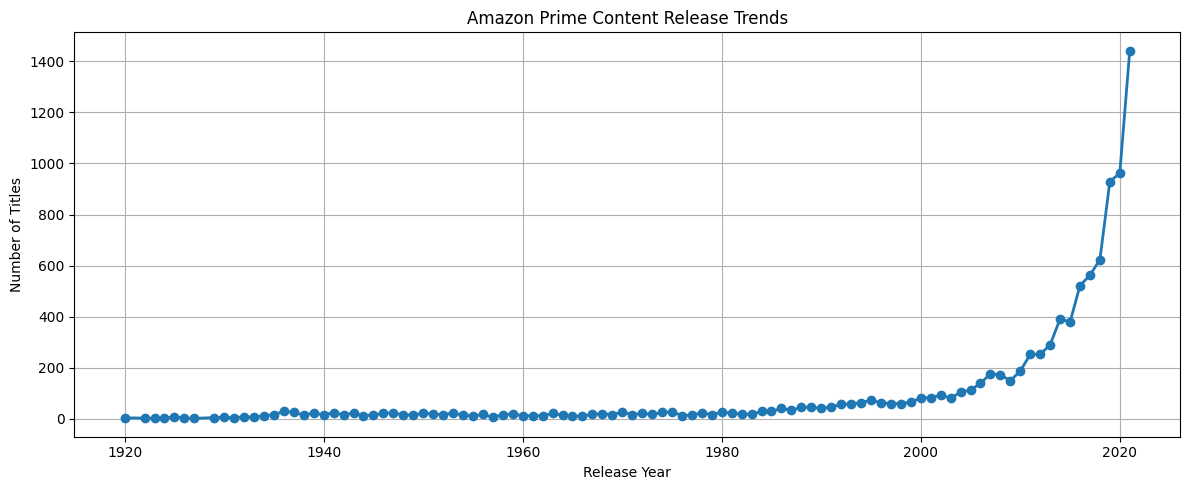

In [14]:
plt.figure(figsize=(12, 5))

year_counts.plot(kind='line', marker='o', linewidth=2)

plt.title('Amazon Prime Content Release Trends')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
# Count top 10 countries
countries = df['country'].str.split(', ').explode()

top_countries = countries[
    countries != 'Unknown'
].value_counts().head(10)

print("Top 10 Countries:")
print(top_countries)

Top 10 Countries:
country
United States     334
India             246
United Kingdom     67
Canada             35
France             20
Germany            17
Italy              14
Spain              11
Japan               6
China               6
Name: count, dtype: int64


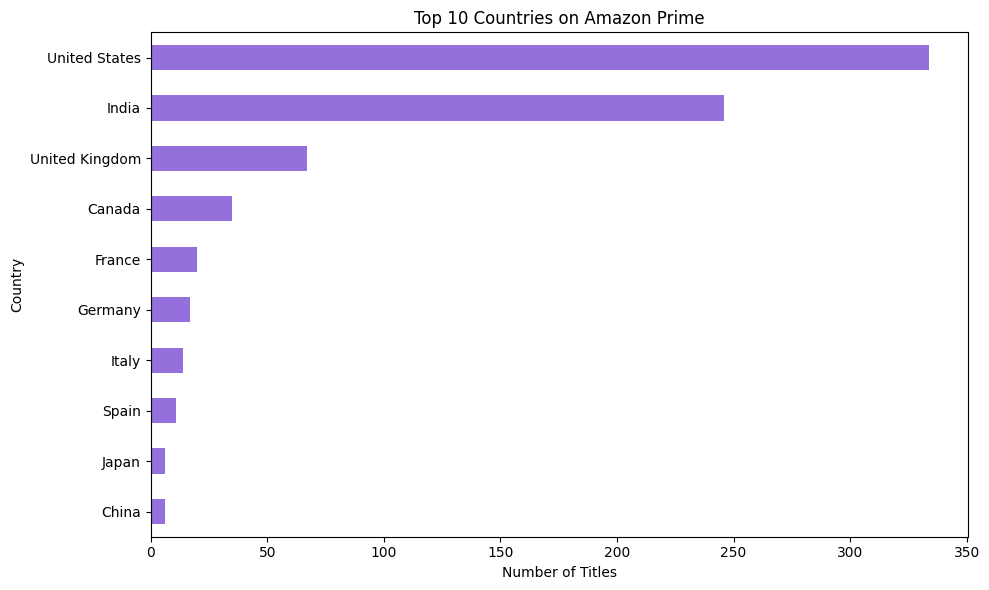

In [16]:
plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(
    kind='barh',
    color='mediumpurple'
)

plt.title('Top 10 Countries on Amazon Prime')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

In [17]:
# Filter movies
movies = df[df['type'] == 'Movie'].copy()

# Extract duration in minutes
movies['duration_minutes'] = pd.to_numeric(
    movies['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

# Display duration statistics
print("Movie Duration Statistics:")
print(movies['duration_minutes'].describe())

Movie Duration Statistics:
count    7814.000000
mean       91.311876
std        40.333086
min         0.000000
25%        75.000000
50%        91.000000
75%       106.000000
max       601.000000
Name: duration_minutes, dtype: float64


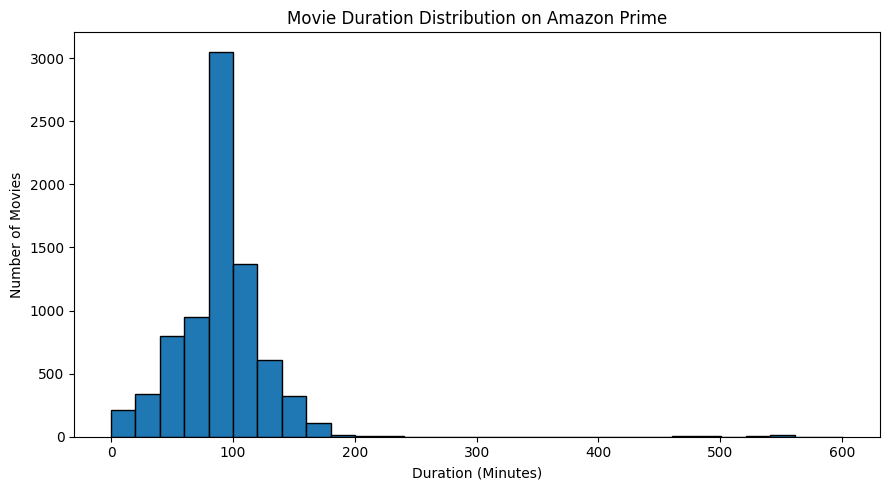

In [18]:
plt.figure(figsize=(9, 5))

plt.hist(
    movies['duration_minutes'].dropna(),
    bins=30,
    edgecolor='black'
)

plt.title('Movie Duration Distribution on Amazon Prime')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')
plt.tight_layout()
plt.show()

In [19]:
import sqlite3

# Create SQLite database
conn = sqlite3.connect('amazon_prime.db')

# Convert DataFrame into SQL table
df.to_sql('amazon_titles', conn, if_exists='replace', index=False)

print("Amazon Prime dataset loaded into SQLite successfully!")

Amazon Prime dataset loaded into SQLite successfully!


In [20]:
query = """
SELECT listed_in, COUNT(*) AS total_titles
FROM amazon_titles
GROUP BY listed_in
ORDER BY total_titles DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

                       listed_in  total_titles
0                          Drama           986
1                         Comedy           536
2                Drama, Suspense           399
3                  Comedy, Drama           377
4                Animation, Kids           356
5                    Documentary           350
6                           Kids           334
7                  Action, Drama           297
8  Documentary, Special Interest           296
9                       TV Shows           263


In [21]:
query = """
SELECT release_year, COUNT(*) AS total_titles
FROM amazon_titles
GROUP BY release_year
ORDER BY total_titles DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

   release_year  total_titles
0          2021          1442
1          2020           962
2          2019           929
3          2018           623
4          2017           562
5          2016           521
6          2014           391
7          2015           378
8          2013           289
9          2012           252


In [29]:
# SQL Query 4: Top 10 Countries

query = """
SELECT country, COUNT(*) AS total_titles
FROM amazon_titles
WHERE country != 'Unknown'
GROUP BY country
ORDER BY total_titles DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

                         country  total_titles
0                  United States           253
1                          India           229
2                 United Kingdom            28
3                         Canada            16
4  United Kingdom, United States            12
5                          Spain             8
6                          Italy             8
7          Canada, United States             7
8  United States, United Kingdom             6
9           India, United States             5


In [30]:
# SQL Query 5: Content Rating Distribution

query = """
SELECT rating, COUNT(*) AS total_titles
FROM amazon_titles
GROUP BY rating
ORDER BY total_titles DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

    rating  total_titles
0      13+          2117
1      16+          1547
2      ALL          1268
3      18+          1243
4        R          1010
5    PG-13           393
6       7+           385
7  Unknown           337
8       PG           253
9       NR           223
